# 08 – Học từ phản hồi của kế toán: đánh giá bằng mô phỏng theo thời gian

**Câu hỏi:** nếu hệ thống học từ đánh giá "đúng / cảnh báo giả" của kế toán để hạ mức các tín hiệu hay sai, số cảnh báo giả
giảm được bao nhiêu, và phải đánh đổi bao nhiêu vấn đề thật bị bỏ sót?

**Vì sao phải mô phỏng.** Dữ liệu Oklahoma PCard không có kết luận thật của kế toán. Notebook này dùng một *kế toán mô phỏng*
(`src/feedback_sim.py`). Mọi con số dưới đây phụ thuộc vào giả định của mô phỏng, nên được báo cáo như một **thí nghiệm có điều
kiện**, không phải hiệu quả đo trên người dùng thật.

**Cơ chế được đánh giá** (`src/feedback.py`):
- Chỉ hiệu chỉnh các tín hiệu dựa trên dấu hiệu gián tiếp: R01 (mô tả chung chung), R03 (trùng hóa đơn), R07 (cửa hàng chưa duyệt),
  giao dịch bất thường và cụm mua dồn của mô hình. R02, R04, R05, R06, R08 là quy định cứng của quy chế nên **được bảo vệ**.
- Phản hồi được gom theo *ngữ cảnh* (1 hoặc 2 thuộc tính: nhóm chi phí, khoảng tiền, số đơn vị đã dùng nhà cung cấp, số lần mua lặp lại
  của người chi / của đơn vị, số lần trả đúng số tiền đó). Tỷ lệ đúng p của ngữ cảnh có hậu nghiệm Beta(1 + đúng, 1 + giả).
- Nếu chắc chắn ≥ 95% rằng p < τ thì **đề xuất** hạ tín hiệu đó xuống mức Thấp (vẫn ghi chú). Quản lý duyệt mới có hiệu lực;
  trong mô phỏng coi như được duyệt và áp dụng từ tháng sau. Đề xuất đang áp dụng chỉ bị gỡ khi độ chắc chắn giảm dưới 50%.
- Kế toán có thể đánh giá nhầm với tỷ lệ ε, nên τ được so trên thang quan sát p(1 − 2ε) + ε.
- Mỗi tháng vẫn lấy mẫu kiểm tra 10% số hồ sơ đã bị hạ mức, để phát hiện đề xuất sai.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.data_loader import load_pcard
from src.labels import add_expense_group, GROUPS
from src.anomaly import inject_anomalies, apply_injection
from src.case import CaseEngine
from src.feedback import signal_table, levels, CALIBRATABLE, MODEL_SIGNALS, SIGNAL_NAMES
from src.feedback_sim import oracle_facts, truth_probability, latent_truth, simulate

pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 140)
BLUE, ORANGE, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1c2a3a', '#4c5b68', '#d5ddd9'
plt.rcParams.update({'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10, 'axes.edgecolor': INK2,
                     'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True,
                     'grid.color': GRID, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Dữ liệu cho mô phỏng

Dùng cùng cách tạo dữ liệu đánh giá như notebook 04: chèn các giao dịch bất thường giả lập (tăng đột biến, cửa hàng lạ, mua dồn,
ghi sổ trễ) từ tháng 1/2026, rồi chạy toàn bộ rule và mô hình. Mô phỏng chạy 8 tháng, 1/2026 – 8/2026 (R07 bắt đầu áp dụng từ 1/2026).

In [2]:
t0 = time.time()
df = add_expense_group(load_pcard())
data = apply_injection(df, inject_anomalies(df, pd.Period('2026-01', 'M')))
eng = CaseEngine(data)
start = pd.Period('2026-01', 'M')
sig = signal_table(eng.df, eng.hits)
sig = sig[sig['month'] >= start].reset_index(drop=True)
facts = oracle_facts(eng.df)
injected = eng.df.loc[(eng.df['is_injected'] == 1) & (eng.df['month'] >= start), 'month']
print(f'{time.time() - t0:.0f} giây; {len(sig):,} tín hiệu; {len(injected):,} giao dịch giả lập')
sig.pivot_table(index='month', columns='signal', values='txn_id', aggfunc='size').fillna(0).astype(int)

45 giây; 57,026 tín hiệu; 1,596 giao dịch giả lập


signal,R01,R02,R03,R04,R05,R06,R07,R08,cum_mua_don,mo_hinh
month,,,,,,,,,,
2026-01,1190,209,381,186,238,12,821,40,3166,359
2026-02,1268,237,542,252,287,11,924,38,3395,400
2026-03,1433,281,530,210,351,16,1223,48,3517,415
2026-04,1384,284,476,258,354,14,1145,71,3332,455
2026-05,1335,303,446,213,286,12,1121,39,3443,386
2026-06,1489,365,407,271,305,15,1242,26,2499,431
2026-07,1416,316,377,162,342,15,1212,40,2030,330
2026-08,1391,328,407,211,348,18,1109,29,2200,358


## 2. Kế toán mô phỏng

Mỗi tín hiệu có một **sự thật ẩn** (đúng / giả), rút ngẫu nhiên một lần với xác suất dưới đây. Các yếu tố quyết định là những thứ
kế toán biết khi xem hồ sơ; hệ thống **không** được thấy chúng trực tiếp mà chỉ thấy các ngữ cảnh gần đúng (cửa sổ thời gian và
ngưỡng khác). Kế toán đánh giá nhầm 10% (ε = 0,1) và mỗi tháng chỉ xem 400 hồ sơ.

| Tín hiệu | Kịch bản "khớp": lý do của kế toán | P(đúng) |
|---|---|---|
| R01 mô tả chung chung | nhà cung cấp quen của đơn vị (≥ 10 lần mua trong 180 ngày) / còn lại | 0,15 / 0,6 |
| R03 trùng hóa đơn | lệ phí, hội phí, đào tạo (đăng ký nhiều người) / phí định kỳ (cùng số tiền ở tháng trước) / còn lại | 0,1 / 0,05 / 0,7 |
| R07 cửa hàng chưa duyệt | nhà cung cấp phổ biến (≥ 10 người chi đã dùng) / còn lại | 0,1 / 0,5 |
| Mô hình (giao dịch, cụm) | vé máy bay, khách sạn / còn lại | 0,05 / 0,3 |
| R02, R04, R05, R06, R08 | quy định cứng | 0,95 |
| Mọi tín hiệu của giao dịch giả lập | vấn đề thật | 0,95 |

Kịch bản **"ẩn"**: lý do của kế toán nằm ở yếu tố hệ thống không quan sát được (R07 phụ thuộc người chi có được tin cậy hay không,
các tín hiệu khác có P(đúng) cố định 0,4 hoặc 0,3). Ở kịch bản này hệ thống không thể học được gì, và **không được gây hại**.

Một hồ sơ là *vấn đề thật* nếu ít nhất một tín hiệu của nó đúng, hoặc là giao dịch giả lập.

In [3]:
for sc in ['khop', 'an']:
    p = truth_probability(sig, facts, sc)
    t = latent_truth(sig, facts, sc)
    print(sc, 'tỷ lệ tín hiệu đúng:', pd.Series(t).groupby(sig['signal'].values).mean().round(2).to_dict())

khop tỷ lệ tín hiệu đúng: {'R01': 0.43, 'R02': 0.95, 'R03': 0.31, 'R04': 0.95, 'R05': 0.94, 'R06': 0.95, 'R07': 0.48, 'R08': 0.94, 'cum_mua_don': 0.19, 'mo_hinh': 0.37}
an tỷ lệ tín hiệu đúng: {'R01': 0.41, 'R02': 0.95, 'R03': 0.4, 'R04': 0.95, 'R05': 0.94, 'R06': 0.95, 'R07': 0.39, 'R08': 0.94, 'cum_mua_don': 0.31, 'mo_hinh': 0.41}


## 3. Kết quả chính (kịch bản "khớp", τ = 0,15, ε = 0,1, 400 hồ sơ/tháng, 5 lần chạy)

- **Tỷ lệ cảnh báo giả** = số hồ sơ được cảnh báo (Cần review trở lên) mà không phải vấn đề thật / số hồ sơ được cảnh báo.
- **Tỷ lệ phát hiện** = số vấn đề thật được cảnh báo / số vấn đề thật (tính cả giao dịch giả lập mà hệ thống gốc bỏ sót).
- **Phát hiện bất thường giả lập** = tỷ lệ giao dịch giả lập được cảnh báo, để xem hiệu chỉnh có làm mất bất thường hiếm không.

In [4]:
TRUTH = {sc: latent_truth(sig, facts, sc) for sc in ['khop', 'an']}
SEEDS = range(5)

def run(sc='khop', **kw):
    out = []
    for seed in SEEDS:
        r, h = simulate(sig, TRUTH[sc], injected, seed=seed, **kw)
        out.append(r.assign(seed=seed))
    return pd.concat(out), h

base, _ = run(calibrate=False)
cal, hist = run()
cols = ['alerts', 'false_alerts', 'false_alert_rate', 'detection', 'injected_detection', 'missed']
m = (pd.concat({'Không học': base.groupby('month')[cols].mean(), 'Có học từ phản hồi': cal.groupby('month')[cols].mean()}, axis=1)
     .round(3))
m

Không học                                                                   Có học từ phản hồi                                                                  
           alerts false_alerts false_alert_rate detection injected_detection missed             alerts false_alerts false_alert_rate detection injected_detection missed
month                                                                                                                                                                   
2026-01    5607.0       3424.0            0.611     0.944              0.720    0.0             5607.0       3424.0            0.611     0.944              0.720    0.0
2026-02    6103.0       3795.0            0.622     0.965              0.536    0.0             4155.8       2010.0            0.482     0.897              0.516  162.2
2026-03    6727.0       4084.0            0.607     0.966              0.513    0.0             5089.4       2613.0            0.511     0.905              0.496  166.6
2026-04    6515.0       3878.0            0.595     0.970              0.542    0.0             4859.6       2372.8            0.484     0.915              0.536  150.2
2026-05    6368.0       3936.0            0.618     0.969              0.503    0.0             4424.4       2184.8            0.492     0.892              0.484  192.4
2026-06    5664.0       3139.0            0.554     0.968              0.421    0.0             4592.4       2205.2            0.478     0.915              0.404  137.8
2026-07    5054.0       2810.0            0.556     0.968              0.413    0.0             4095.0       1952.4            0.475     0.924              0.408  101.4
2026-08    5238.0       2932.0            0.560     0.963              0.413    0.0             4209.4       1998.8            0.475     0.923              0.412   95.4

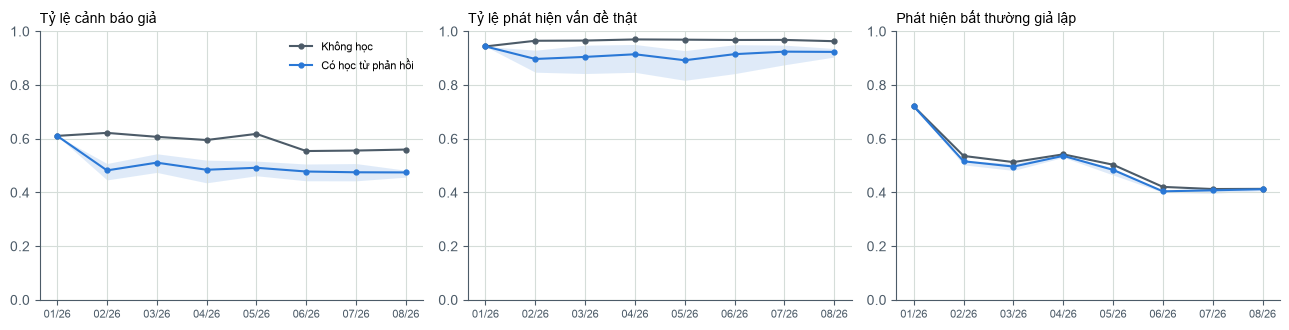

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(axes, ['false_alert_rate', 'detection', 'injected_detection'],
                          ['Tỷ lệ cảnh báo giả', 'Tỷ lệ phát hiện vấn đề thật', 'Phát hiện bất thường giả lập']):
    for frame, label, color in [(base, 'Không học', INK2), (cal, 'Có học từ phản hồi', BLUE)]:
        g = frame.groupby('month')[col]
        x = np.arange(g.ngroups)
        ax.plot(x, g.mean(), marker='o', ms=3.5, color=color, label=label)
        ax.fill_between(x, g.min(), g.max(), color=color, alpha=0.15, lw=0)
    ax.set_xticks(x, [mm[5:] + '/26' for mm in g.mean().index], fontsize=8)
    ax.set_title(title, fontsize=10, loc='left'); ax.set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
late = lambda r: r[r['month'] >= '2026-05']
def summary(frame):
    g = late(frame).groupby('seed')
    return pd.Series({'Cảnh báo / tháng': g['alerts'].mean().mean(), 'Cảnh báo giả / tháng': g['false_alerts'].mean().mean(),
                      'Tỷ lệ cảnh báo giả': g['false_alert_rate'].mean().mean(), 'Tỷ lệ phát hiện': g['detection'].mean().mean(),
                      'Phát hiện bất thường giả lập': g['injected_detection'].mean().mean(),
                      'Vấn đề thật bị hạ mức / tháng': g['missed'].mean().mean()})
main = pd.DataFrame({'Không học': summary(base), 'Có học từ phản hồi': summary(cal)})
main['Thay đổi'] = main['Có học từ phản hồi'] - main['Không học']
display(Markdown('**Trung bình 4 tháng cuối (5/2026 – 8/2026), sau khi đã có phản hồi:**'))
main.round(3)

**Trung bình 4 tháng cuối (5/2026 – 8/2026), sau khi đã có phản hồi:**

,Không học,Có học từ phản hồi,Thay đổi
Cảnh báo / tháng,5581.000,4330.300,-1250.700
Cảnh báo giả / tháng,3204.250,2085.300,-1118.950
Tỷ lệ cảnh báo giả,0.572,0.480,-0.092
Tỷ lệ phát hiện,0.967,0.914,-0.053
Phát hiện bất thường giả lập,0.437,0.427,-0.010
Vấn đề thật bị hạ mức / tháng,0.000,131.750,131.750


### Các đề xuất hệ thống đưa ra (lần chạy đầu, cuối tháng 8/2026)

Đây là những gì quản lý sẽ thấy trên trang *Hiệu chỉnh cảnh báo*. Có thể đối chiếu với lý do ẩn của kế toán mô phỏng ở mục 2.

In [7]:
_, h0 = simulate(sig, TRUTH['khop'], injected, seed=0)
pd.DataFrame(h0[-1]['proposals'])[['text', 'n', 'n_true', 'p_below', 'affected']].rename(columns={
    'text': 'Đề xuất', 'n': 'Số phản hồi', 'n_true': 'Đúng', 'p_below': 'P(p < τ)', 'affected': 'Tín hiệu tháng 8'})

,Đề xuất,Số phản hồi,Đúng,P(p < τ),Tín hiệu tháng 8
0,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số tiền < $500: 15/80 cảnh báo được kế toán xác nhận đúng. Đề...",80,15,0.728,85
1,cum_mua_don (Cụm mua dồn dập trong ngày) khi nhóm chi phí “Vé máy bay & đại lý du lịch”: 43/381 cảnh báo được kế toán xác nhận đúng. Đề ...,381,43,1.000,672
2,cum_mua_don (Cụm mua dồn dập trong ngày) khi số tiền $500–1.000: 32/153 cảnh báo được kế toán xác nhận đúng. Đề xuất hạ xuống mức Thấp (...,153,32,0.599,343
3,"cum_mua_don (Cụm mua dồn dập trong ngày) khi nhóm chi phí “Lưu trú khách sạn”, số lần đơn vị mua ở đây trong 90 ngày trước 1–19: 13/98 c...",98,13,0.982,121


In [8]:
print('Số đề xuất đang áp dụng theo tháng:', [len(x['proposals']) for x in h0])
print('Số đề xuất bị gỡ theo tháng:', [len(x['revoked']) for x in h0])

Số đề xuất đang áp dụng theo tháng: [2, 2, 2, 2, 2, 3, 4, 4]
Số đề xuất bị gỡ theo tháng: [0, 0, 0, 0, 0, 0, 0, 0]


## 4. Kịch bản "ẩn": khi không có gì để học

Nếu hệ thống hạ mức một cách bừa bãi thì ở kịch bản này tỷ lệ phát hiện sẽ giảm mà cảnh báo giả không giảm.

In [9]:
base_an, _ = run('an', calibrate=False)
cal_an, _ = run('an')
an = pd.DataFrame({'Không học': summary(base_an), 'Có học từ phản hồi': summary(cal_an)})
an['Thay đổi'] = an['Có học từ phản hồi'] - an['Không học']
for seed in SEEDS:
    _, h = simulate(sig, TRUTH['an'], injected, seed=seed)
    print(f'seed {seed}: số đề xuất theo tháng {[len(x["proposals"]) for x in h]}, bị gỡ {sum(len(x["revoked"]) for x in h)}')
an.round(3)

seed 0: số đề xuất theo tháng [0, 0, 1, 1, 1, 1, 0, 0], bị gỡ 1


seed 1: số đề xuất theo tháng [0, 0, 0, 0, 0, 0, 0, 0], bị gỡ 0


seed 2: số đề xuất theo tháng [0, 1, 0, 0, 0, 0, 0, 0], bị gỡ 1


seed 3: số đề xuất theo tháng [0, 0, 0, 0, 0, 0, 0, 0], bị gỡ 0


seed 4: số đề xuất theo tháng [0, 0, 0, 0, 0, 0, 0, 0], bị gỡ 0


,Không học,Có học từ phản hồi,Thay đổi
Cảnh báo / tháng,5581.000,5560.700,-20.300
Cảnh báo giả / tháng,3003.750,2990.050,-13.700
Tỷ lệ cảnh báo giả,0.537,0.537,-0.000
Tỷ lệ phát hiện,0.969,0.967,-0.002
Phát hiện bất thường giả lập,0.437,0.437,0.000
Vấn đề thật bị hạ mức / tháng,0.000,6.600,6.600


## 5. Độ nhạy và đánh đổi

**Mức trần.** Nếu hệ thống biết đúng lý do của kế toán và hạ mức chính xác các tín hiệu có P(đúng) ≤ τ, nó giảm được bao nhiêu
cảnh báo giả? Con số này cho biết cơ chế học đạt được bao nhiêu phần so với lý tưởng.

In [10]:
def ceiling(tau, sc='khop'):
    s = sig[sig['month'] >= pd.Period('2026-05', 'M')].copy()
    s['truth'] = TRUTH[sc][s.index]
    s['p'] = truth_probability(s, facts, sc)
    inj = injected[injected >= pd.Period('2026-05', 'M')]
    idx = pd.Index(s['idx'].unique()).union(inj.index)
    t = s.groupby('idx')['truth'].any().reindex(idx, fill_value=False); t[t.index.isin(inj.index)] = True
    b = levels(s, None, idx) != 'Bình thường'
    a = levels(s, (s['p'] <= tau) & s['signal'].isin(CALIBRATABLE + MODEL_SIGNALS), idx) != 'Bình thường'
    return 1 - (a & ~t).sum() / (b & ~t).sum(), (b & ~a & t).sum() / 4

def grid_row(label, **kw):
    r, _ = run(**kw); b, c = summary(base), summary(r)
    return {'Thiết lập': label, 'Giảm cảnh báo giả': 1 - c['Cảnh báo giả / tháng'] / b['Cảnh báo giả / tháng'],
            'Thay đổi tỷ lệ phát hiện': c['Tỷ lệ phát hiện'] - b['Tỷ lệ phát hiện'],
            'Vấn đề thật bị hạ mức / tháng': c['Vấn đề thật bị hạ mức / tháng'],
            'Phát hiện bất thường giả lập': c['Phát hiện bất thường giả lập']}

taus = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
curve = pd.DataFrame([grid_row(f'τ = {t}', tau=t) for t in taus])
curve['Mức trần: giảm cảnh báo giả'] = [ceiling(t)[0] for t in taus]
curve['Mức trần: bị hạ mức / tháng'] = [ceiling(t)[1] for t in taus]
curve.round(3)

,Thiết lập,Giảm cảnh báo giả,Thay đổi tỷ lệ phát hiện,Vấn đề thật bị hạ mức / tháng,Phát hiện bất thường giả lập,Mức trần: giảm cảnh báo giả,Mức trần: bị hạ mức / tháng
0,τ = 0.05,0.070,-0.005,12.00,0.437,0.323,58.25
1,τ = 0.1,0.229,-0.018,45.30,0.432,0.367,77.25
2,τ = 0.15,0.349,-0.053,131.75,0.427,0.472,137.00
3,τ = 0.2,0.440,-0.098,241.10,0.426,0.472,137.00
4,τ = 0.25,0.639,-0.193,476.30,0.384,0.472,137.00
5,τ = 0.3,0.702,-0.223,549.70,0.380,0.787,569.25


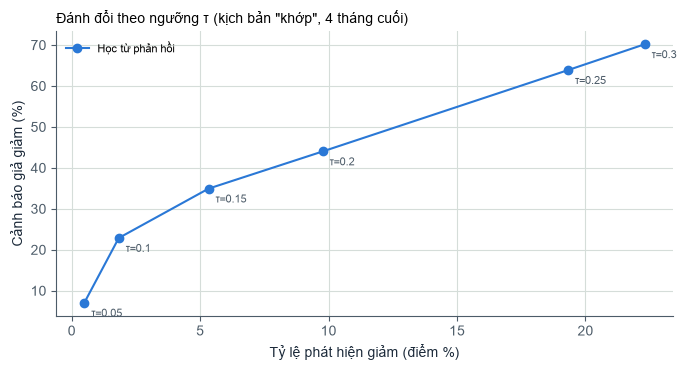

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(-curve['Thay đổi tỷ lệ phát hiện'] * 100, curve['Giảm cảnh báo giả'] * 100, marker='o', color=BLUE, label='Học từ phản hồi')
for t, x, y in zip(taus, -curve['Thay đổi tỷ lệ phát hiện'] * 100, curve['Giảm cảnh báo giả'] * 100):
    ax.annotate(f'τ={t}', (x, y), textcoords='offset points', xytext=(5, -10), fontsize=8, color=INK2)
ax.set_xlabel('Tỷ lệ phát hiện giảm (điểm %)'); ax.set_ylabel('Cảnh báo giả giảm (%)')
ax.set_title('Đánh đổi theo ngưỡng τ (kịch bản "khớp", 4 tháng cuối)', fontsize=10, loc='left')
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

Các yếu tố khác (τ = 0,15): mức nhầm lẫn của kế toán, ước lượng sai mức nhầm lẫn, số hồ sơ được xem mỗi tháng, và có lấy mẫu
kiểm tra hồ sơ đã hạ mức hay không.

In [12]:
other = pd.DataFrame([
    grid_row('Mặc định (ε = 0,1, 400 hồ sơ, kiểm tra mẫu 10%)'),
    grid_row('Kế toán không nhầm (ε = 0)', noise=0.0),
    grid_row('Kế toán nhầm 20%, hệ thống biết đúng', noise=0.2),
    grid_row('Nhầm 10%, hệ thống giả định 0 (thận trọng)', noise=0.1, assumed_noise=0.0),
    grid_row('Nhầm 10%, hệ thống giả định 20% (quá tay)', noise=0.1, assumed_noise=0.2),
    grid_row('Xem 200 hồ sơ / tháng', budget=200),
    grid_row('Xem 800 hồ sơ / tháng', budget=800),
    grid_row('Không kiểm tra mẫu hồ sơ đã hạ mức', explore=0.0),
])
other.round(3)

,Thiết lập,Giảm cảnh báo giả,Thay đổi tỷ lệ phát hiện,Vấn đề thật bị hạ mức / tháng,Phát hiện bất thường giả lập
0,"Mặc định (ε = 0,1, 400 hồ sơ, kiểm tra mẫu 10%)",0.349,-0.053,131.75,0.427
1,Kế toán không nhầm (ε = 0),0.336,-0.039,95.80,0.422
2,"Kế toán nhầm 20%, hệ thống biết đúng",0.365,-0.066,162.50,0.427
3,"Nhầm 10%, hệ thống giả định 0 (thận trọng)",0.167,-0.013,31.05,0.429
4,"Nhầm 10%, hệ thống giả định 20% (quá tay)",0.622,-0.185,455.20,0.404
5,Xem 200 hồ sơ / tháng,0.316,-0.043,106.60,0.429
6,Xem 800 hồ sơ / tháng,0.351,-0.043,106.40,0.420
7,Không kiểm tra mẫu hồ sơ đã hạ mức,0.402,-0.071,175.20,0.424


## 6. Nhận xét

Các con số cụ thể nằm ở bảng phía trên; phần này tóm tắt điều rút ra được.

1. **Học được khi lý do của kế toán quan sát được (một phần).** Ở kịch bản "khớp", hệ thống tìm ra các nhóm tín hiệu hay sai
   ngay từ tháng thứ hai. Ổn định nhất là cụm mua dồn ở vé máy bay và khách sạn (5/5 và 4/5 lần chạy, chiếm phần lớn mức giảm);
   trùng hóa đơn ở lệ phí/đào tạo và mô tả chung chung ở nhà cung cấp quen của đơn vị chỉ đủ chắc chắn ở một số lần chạy; R07 với
   nhà cung cấp phổ biến thì không lần nào, vì hệ thống chỉ thấy "số đơn vị đã dùng" trong khi kế toán dựa vào "số người chi đã dùng". Với τ = 0,15, trung bình 4 tháng cuối: cảnh báo giả giảm 35% (tỷ lệ cảnh báo giả 0,57 → 0,48), tỷ lệ
   phát hiện giảm 5,3 điểm (≈ 130 vấn đề thật mỗi tháng bị hạ xuống mức ghi chú), phát hiện bất thường giả lập gần như giữ nguyên
   (0,44 → 0,43). Mức trần với cùng τ là giảm 47% với ≈ 137 vấn đề bị hạ mức, nên cơ chế học đạt khoảng 3/4 mức lý tưởng với cùng
   chi phí; phần còn thiếu là do ngữ cảnh hệ thống thấy chỉ gần đúng với lý do thật của kế toán.
2. **Không gây hại khi không có gì để học.** Ở kịch bản "ẩn", gần như không có đề xuất nào; đề xuất ngẫu nhiên hiếm hoi bị gỡ nhờ
   kiểm tra mẫu và cơ chế gỡ.
3. **Có đánh đổi, và τ là quyết định nghiệp vụ.** Hạ mức một ngữ cảnh có tỷ lệ đúng dưới τ nghĩa là chấp nhận bỏ sót một phần
   vấn đề thật trong ngữ cảnh đó. τ càng lớn càng ít cảnh báo giả nhưng càng nhiều vấn đề bị hạ mức. Mặc định τ = 0,15
   (≈ 1 vấn đề bỏ sót đổi 6 lần review thừa); quản lý có thể đổi trong `config/rules.toml`. Tín hiệu bị hạ mức vẫn được ghi chú trong hồ sơ.
4. **Bất thường hiếm cần được tách riêng.** Lúc đầu tín hiệu mô hình được gộp làm một; vì phần lớn là cụm mua dồn lành tính, hệ thống
   hạ mức cả giao dịch bất thường thật. Tách "giao dịch bất thường" và "cụm mua dồn" thành hai tín hiệu giữ được tỷ lệ phát hiện bất thường giả lập.
5. **Nhầm lẫn của kế toán quan trọng.** Nếu không tính tới ε, ngữ cảnh đúng 0% vẫn hiện ra ~10% "đúng" và hệ thống không bao giờ chắc
   chắn được. Giả định ε quá cao thì hệ thống hạ mức quá tay. Khi triển khai cần ước lượng ε bằng review chéo một mẫu nhỏ.

**Hạn chế.** Kết quả phụ thuộc hoàn toàn vào giả định của kế toán mô phỏng (xác suất, lý do, mức nhầm lẫn), không thay cho đánh giá
với kế toán thật. Mô phỏng coi mọi đề xuất được duyệt ngay; trên ứng dụng, quản lý có thể từ chối. "Vấn đề thật" chỉ tính trong các
hồ sơ hệ thống gốc đã cảnh báo cộng giao dịch giả lập; vấn đề mà rule và mô hình không bắt được từ đầu thì không đo được.